<a href="https://colab.research.google.com/github/TimothyKeng/Timothy_INFO4670_Falls2026/blob/main/Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [25]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> False positive would be more costly because a real message would be blocked and the user may never see it. A false negative would also be a problem because it could reach the user and could expose them to scams or unwanted messages.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> Precision would be my primary evaluation metric. Since false positive are most costly, I would want the messages predicted as spam to actually be spam. A higher precision means fewer real messages are incorrectly blocked.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> If about 13% of messages are spam, about 87% are ham. A dummy model that predicts ham would have about 87% accuracy. This is misleading because the model wouldn't catch any spam messages even though the accuracy appear high.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [26]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


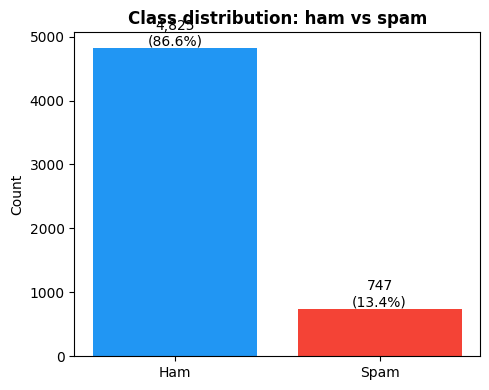

In [27]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [28]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


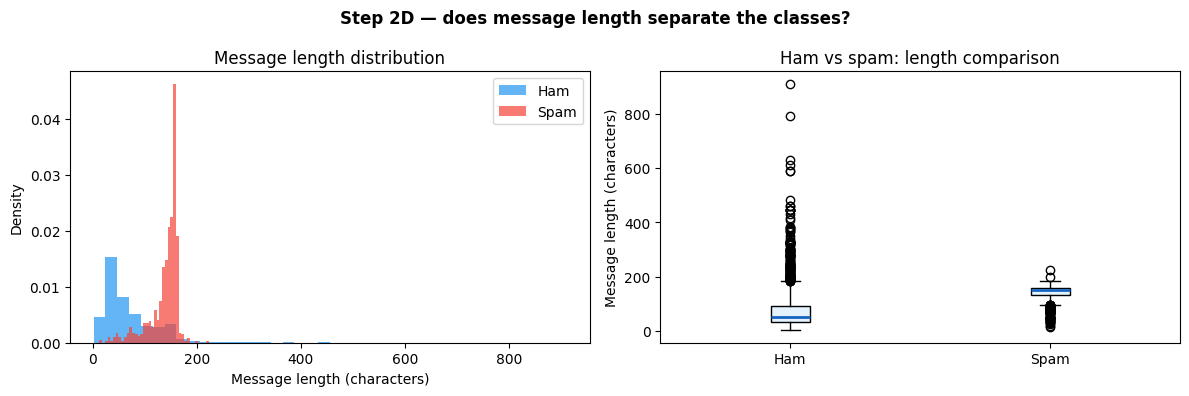

In [29]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [30]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [31]:
# Write your code here

def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()

    d['has_caps']= d['message'].str.contains(r'\b[A-Z]{3,}\b', regex= True).astype(int)

    d['has_cta']= msg.str.contains(r'\b(txt|text|reply)\b', regex=True).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_caps               70.4%    7.2%  +63.3%
has_cta                40.7%    2.5%  +38.2%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


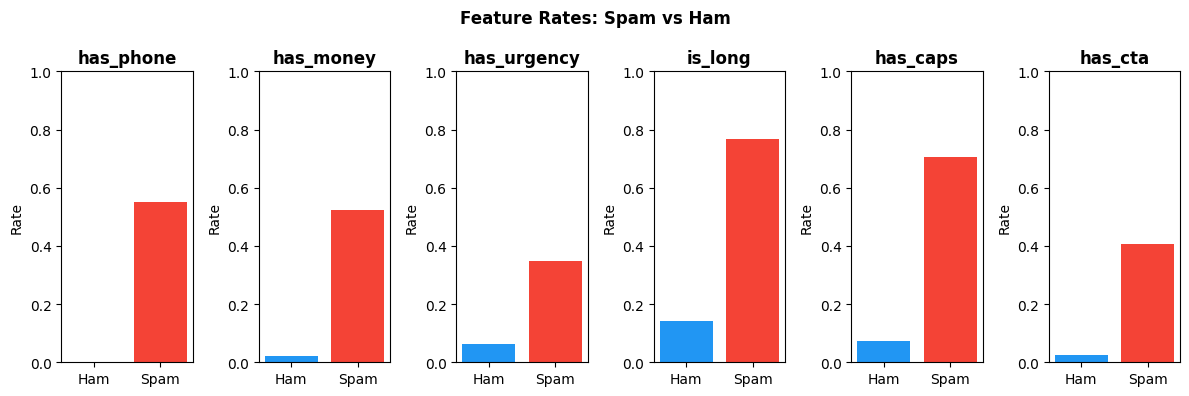

In [32]:
n_features= len(feature_cols)

fig, axes = plt.subplots(1, n_features, figsize=(12, 4))

for ax, feat in zip(axes, feature_cols):
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()

    ax.bar(['Ham', 'Spam'], [ha, sp], color=['#2196F3', '#F44336'])
    ax.set_ylabel('Rate')
    ax.set_ylim(0,1)
    ax.set_title(feat, fontweight='bold')

plt.suptitle('Feature Rates: Spam vs Ham', fontweight= 'bold')
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> Checks if the message has a word with three or more capital letters. This would be useful because spam messages often use capital letters to draw attention to look urgent.

*Feature 2 — name and explanation:*
> Checks if the message contains words like txt, text, or reply. This would be useful because spam often tell the receiver to respond or take action.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> The feature with the largest gap was has_caps, with a 63.3 percentage points difference between spam and ham messages. A large gap helps the Decision Tree separate the two classes. This is related to Information Gain because the tree looks for features that reduce uncertainty about a message being spam or ham.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> A spam message that my features could fail to identify would be a phishing message without capital letters, or words with text or reply. Both has_caps and has_cta would return 0 potentially causing the model to incorrectly classify the spam message as ham.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [33]:
# Write your code here
x= df[feature_cols].values
y= df['spam'].values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

print('Training set size:', len(x_train))
print('Spam rate:', y_train.mean())
print('Test set size:', len(x_test))
print('Spam rate:', y_test.mean())

Training set size: 4179
Spam rate: 0.13400335008375208
Test set size: 1393
Spam rate: 0.1342426417803302


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> Using stratify=y ensures the training and testing sets have about the same percentage of spam and ham messages as the original dataset. Skipping stratification could result in an uneven distribution. This could make the model harder to train or give misleading results.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would use a k-fold cross-validation when using a smaller dataset. Instead of relying on one train/test split, cross-validation trains and test different portions of the data model. This gives a more reliable estimate of how well the model performs.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 15


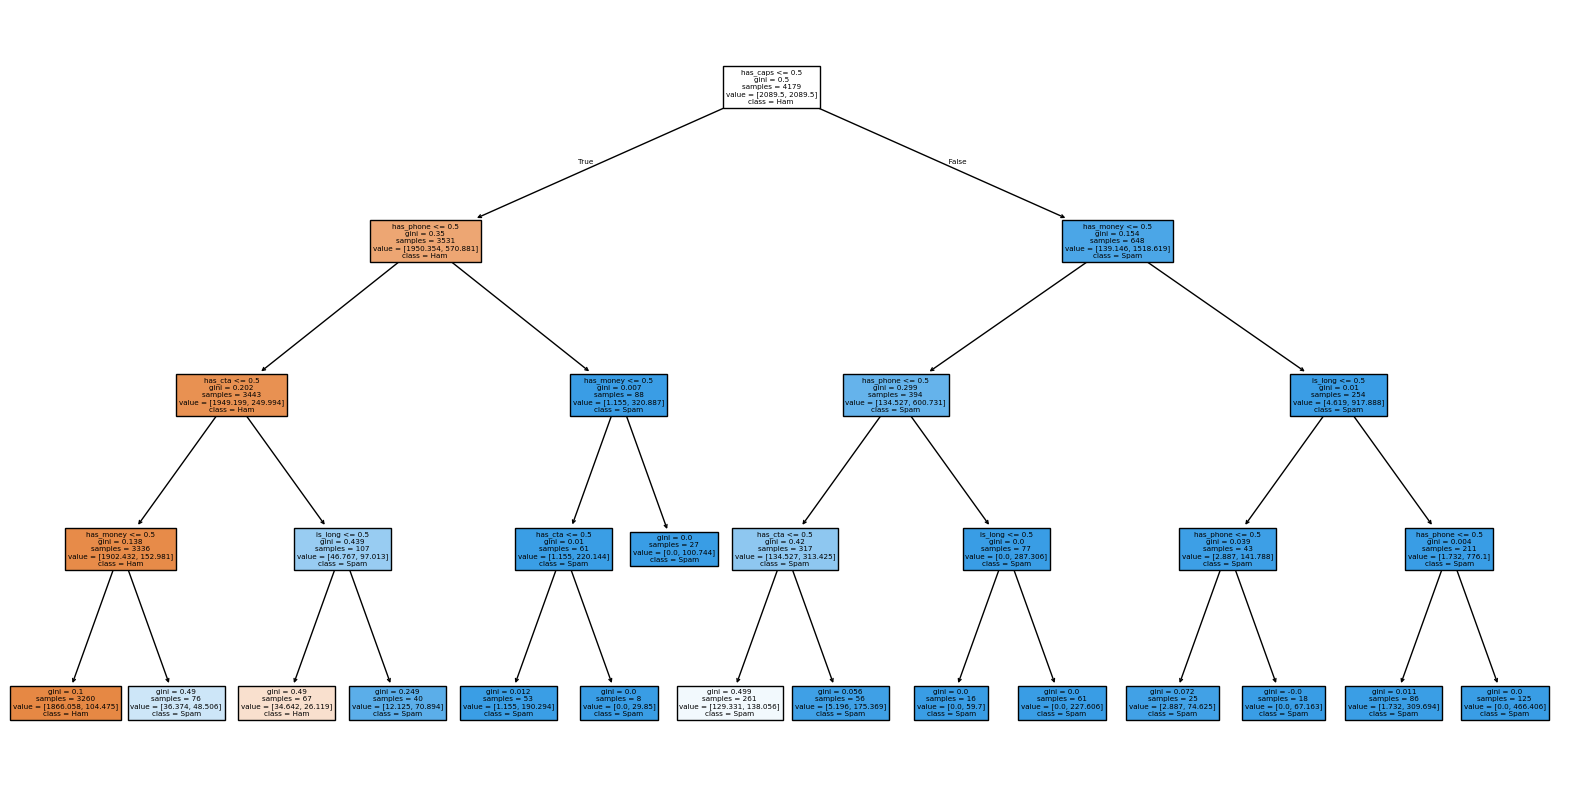

|--- has_caps <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_cta <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_cta >  0.50
|   |   |   |--- is_long <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- is_long >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_cta <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_cta >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- class: 1
|--- has_caps >  0.50
|   |--- has_money <= 0.50
|   |   |--- has_phone <= 0.50
|   |   |   |--- has_cta <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_cta >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_phone >  0.50
|   |   |   |--- is_long <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- is_long >  0.50
|   |   |   |   |--- class: 1
|   |--- has_money >  0.50
|   | 

In [34]:
dt= DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(x_train, y_train)

print('Number of leaves:', dt.get_n_leaves())
plt.figure(figsize=(20, 10))
plot_tree(dt, feature_names=feature_cols, class_names=['Ham', 'Spam'], filled=True)
plt.show()

print(export_text(dt, feature_names=feature_cols))


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


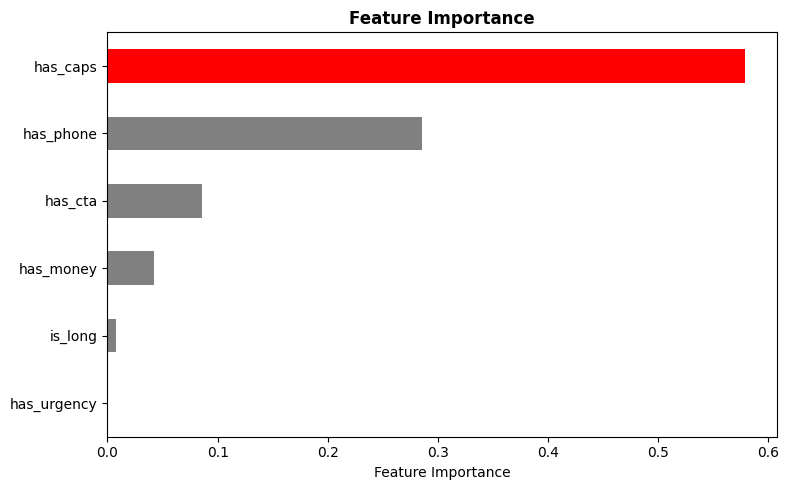

In [35]:
importance= pd.Series(dt.feature_importances_, index=feature_cols).sort_values()

colors= ['red' if value == importance.max() else 'gray' for value in importance]

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color= colors)
plt.xlabel('Feature Importance')
plt.title('Feature Importance', fontweight='bold')
plt.tight_layout()
plt.show()


### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


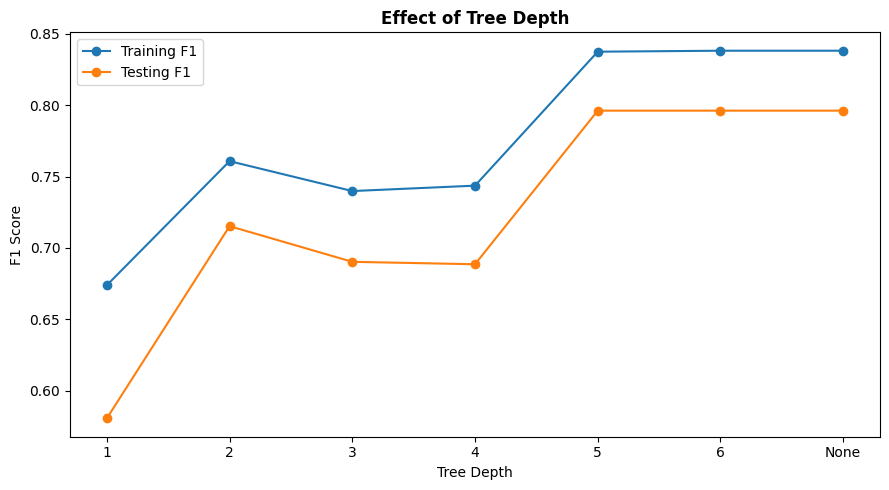

Depth      Train F1     Test F1      Gap       
1          0.674        0.580        0.093     
2          0.761        0.715        0.046     
3          0.740        0.690        0.050     
4          0.744        0.689        0.055     
5          0.838        0.796        0.041     
6          0.838        0.796        0.042     
None       0.838        0.796        0.042     


In [36]:
# Write your code here
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd

# Ensure features and splits are prepared if the kernel restarted
if 'raw' in globals():
    df = build_features_v2(raw)
    feature_cols = [c for c in df.columns if c not in ['label', 'message', 'spam', 'msg_length']]
    x = df[feature_cols].values
    y = df['spam'].values
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42, stratify=y)

depths = [1, 2, 3, 4, 5, 6, None]
train_f1 = []
test_f1 = []

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42,
        class_weight='balanced')

    tree.fit(x_train, y_train)

    train_f1.append(f1_score(y_train, tree.predict(x_train)))
    test_f1.append(f1_score(y_test, tree.predict(x_test)))

plt.figure(figsize=(9, 5))

x_ticks = range(len(depths))

plt.plot(x_ticks, train_f1, marker='o', label='Training F1')
plt.plot(x_ticks, test_f1, marker='o', label='Testing F1')

plt.xticks(x_ticks, [str(d) for d in depths])
plt.xlabel('Tree Depth')
plt.ylabel('F1 Score')
plt.title('Effect of Tree Depth', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

print(f'{"Depth":<10} {"Train F1":<12} {"Test F1":<12} {"Gap":<10}')
for depth, train, test in zip(depths, train_f1, test_f1):
    print(f'{str(depth):<10} {train:<12.3f} {test:<12.3f} {train-test:<10.3f}')

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [37]:
# Write your code here
nb= BernoulliNB()

nb.fit(x_train, y_train)

print('Trained Naive Bayes model')

Trained Naive Bayes model


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


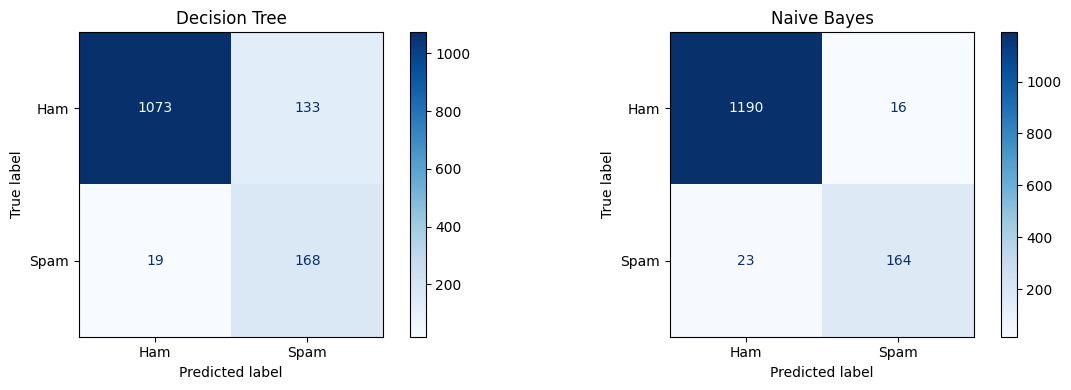

Decision Tree:
  TP: 168
  FP: 133
  FN: 19
  TN: 1073

Naive Bayes:
  TP: 164
  FP: 16
  FN: 23
  TN: 1190


In [38]:
# Write your code here

y_pred_dt= dt.predict(x_test)
y_pred_nb= nb.predict(x_test)

cm_dt= confusion_matrix(y_test, y_pred_dt)
cm_nb= confusion_matrix(y_test, y_pred_nb)

fig, axes= plt.subplots(1,2, figsize=(12, 4))

disp_dt= ConfusionMatrixDisplay(cm_dt, display_labels=['Ham', 'Spam'])
disp_nb= ConfusionMatrixDisplay(cm_nb, display_labels=['Ham', 'Spam'])

disp_dt.plot(ax=axes[0], cmap='Blues')
disp_nb.plot(ax=axes[1], cmap='Blues')

axes[0].set_title('Decision Tree')

axes[1].set_title('Naive Bayes')

plt.tight_layout()
plt.show()

tn_dt, fp_dt, fn_dt, tp_dt= cm_dt.ravel()

print('Decision Tree:')
print(f'  TP: {tp_dt}')
print(f'  FP: {fp_dt}')
print(f'  FN: {fn_dt}')
print(f'  TN: {tn_dt}')

tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

print('\nNaive Bayes:')
print(f'  TP: {tp_nb}')
print(f'  FP: {fp_nb}')
print(f'  FN: {fn_nb}')
print(f'  TN: {tn_nb}')

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


           Model  Accuracy  Precision  Recall  F1-Score
0  Decision Tree     0.891      0.558   0.898     0.689
1    Naive Bayes     0.972      0.911   0.877     0.894


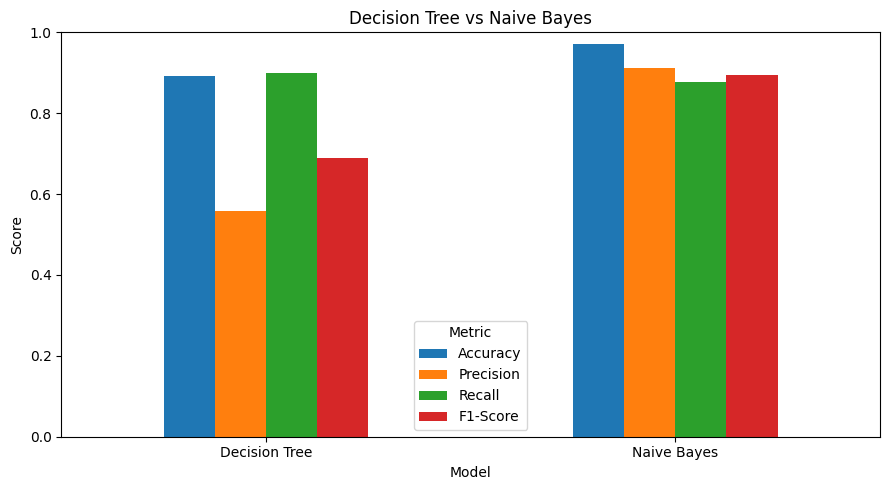

In [39]:
# Write your code here

results= pd.DataFrame({'Model': ['Decision Tree', 'Naive Bayes'],
                       'Accuracy': [
                          accuracy_score(y_test, y_pred_dt),
                          accuracy_score(y_test, y_pred_nb)],
                       'Precision': [
                           precision_score(y_test, y_pred_dt),
                           precision_score(y_test, y_pred_nb)],
                       'Recall': [
                           recall_score(y_test, y_pred_dt),
                           recall_score(y_test, y_pred_nb)],
                       'F1-Score': [
                           f1_score(y_test, y_pred_dt),
                           f1_score(y_test, y_pred_nb)]})



print(results.round(3))

results.set_index('Model').plot(kind= 'bar', figsize= (9,5))

plt.title('Decision Tree vs Naive Bayes')
plt.ylabel('Score')
plt.xlabel('Model')
plt.ylim(0,1)
plt.xticks(rotation= 0)
plt.legend(title= 'Metric')
plt.tight_layout()
plt.show()

### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [40]:
# Write your code here

cv= StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_cv= cross_val_score(dt, x, y, cv=cv, scoring='f1')
nb_cv= cross_val_score(nb, x, y, cv=cv, scoring='f1')

print(f'Decision Tree: {dt_cv.mean():.3f}')
print(f'Naive Bayes: {nb_cv.mean():.3f}')

print()

print('Naive Bayes 5-fold F1 scores:', nb_cv)
print('Decision Tree 5-fold F1 scores:', dt_cv)



Decision Tree: 0.838
Naive Bayes: 0.890

Naive Bayes 5-fold F1 scores: [0.91034483 0.88501742 0.89932886 0.87632509 0.87671233]
Decision Tree 5-fold F1 scores: [0.87128713 0.8496732  0.83792049 0.81045752 0.82315113]


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> The Decision Tree correctly identified 168 (TP) spam messages while 19 (FN) spam messages slipped through. It also incorrectly classified 133 (FP) legitimate messages as spam

*Naive Bayes:*
> The Naive Bayes model correctly identified 164 (TP) spam messages, while 23 (FN) spam messages slipped through. it also incorrectly classified 16 (FP)legitimate messages as spam.

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> Based on Precision, the Naive bayes performed better. It reached a Precision of 91.1% compared to the 55.8% Decision Tree making a difference of 35.3%. The Naive Bayes was less likely to incorrectly classify legitimate messages as spam. The cross-validation results should also be compared to determine whether this advantage is consistent across different data splits.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I would reccomend using the Naive Bayes model for SMS spam detection because it produced only 16 false positives while the Decision Tree produced 133. One weakness is that Naive Bayes missed 23 spam messages while the Decision Tree missed 19. To improve performance, I would add features that identify suspicious links and regularly updated the training data to account for newer spam techniques.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> Two features that might fail on modern spam are has_caps and has_cta. The has_caps feature looks for words written in all capital letters but modern spam doesn't use excessive capitalization. The has_cta feature looks for words like txt, text, or reply, but modern messages sometimes direct users to legitimate looking websites. As a result, both features could fail to identify spam messages that appear more professional.
